In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../'))
sys.path.append(base_path)
sys.path.append(current_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from IPython.display import display


import project_images_loader as pil
from tqdm import tqdm

import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.visualization as vis
import utils.util_machine_learning as uml

import SimpleITK as sitk
import longitudinal.whole_brain_based.features_loader as features_loader_longitudinal_whole_brain_based
import longitudinal.tissue_based.features_loader as features_loader_longitudinal_tissue_based
import cross_sectional.tissue_based.features_loader as features_loader_cross_sectional_tissue_based
import demographic.features_loader as features_loader_demographic

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from scipy import stats

np.set_printoptions(precision=4)


SERVER: False


# Load features

## Demographic features

,gender,age_hunt3,age_hunt4
0,0,51,62
1,1,63,75
2,1,60,72
3,0,54,66
4,1,56,68


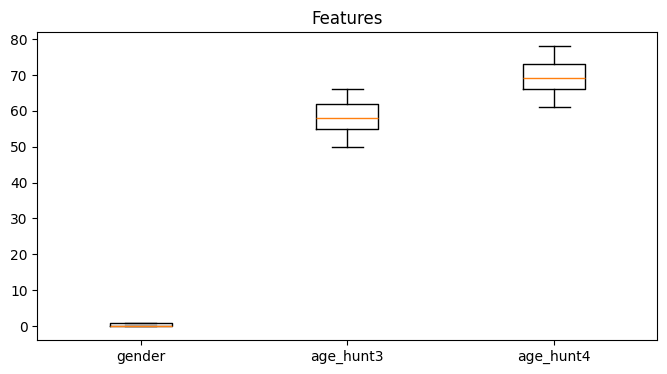

In [2]:
loader_demographic  = features_loader_demographic.FeaturesLoader
features_path_name_demographic = f'{current_path}/demographic/features/demographic'

reader_demographic = loader_demographic()
data_demographic = reader_demographic.get_df(
                     return_patient_id=True, 
                     remove_patients=pil.EXCLUDED_PATIENTS)

data_ids_demographic = data_demographic.pop('patient_id').tolist()
data_columns_demographic = data_demographic.columns.tolist()
display(data_demographic.head())

vis.plot_data_voxplot(data_demographic, data_columns_demographic, figsize=(8,4))

## Longitudinal features

### Whole brain based

(685, 6)


,bpf_hunt3,bpf_hunt4,bpf_dif,bpf_div,ncc,ssim
0,0.748474,0.730403,0.018070,0.975857,0.969390,0.946643
1,0.727681,0.686561,0.041120,0.943492,0.959862,0.932895
2,0.731495,0.686346,0.045149,0.938278,0.959196,0.935580
3,0.779077,0.742708,0.036369,0.953318,0.970761,0.955065
4,0.749056,0.704833,0.044223,0.940961,0.956201,0.937980


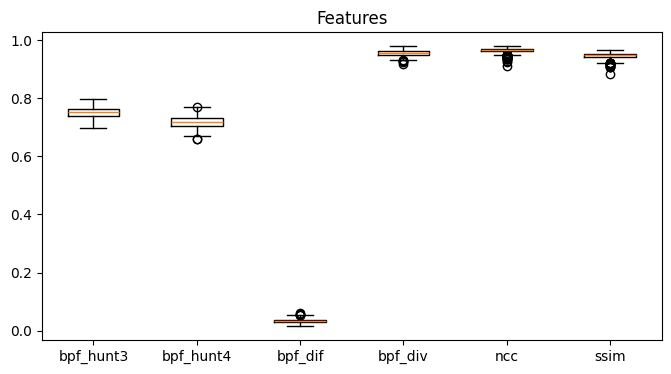

In [4]:
loader_logitudinal_wbb = features_loader_longitudinal_whole_brain_based.FeaturesLoader
features_path_name_logitudinal_wbb = f'{current_path}/longitudinal/whole_brain_based/features/whole_brains_stats'
columns = None

reader_logitudinal_wbb = loader_logitudinal_wbb()
data_logitudinal_wbb = reader_logitudinal_wbb.get_df(columns=columns,
                     remove_columns=False, 
                     return_patient_id=True, 
                     id_patients=data_ids_demographic,
                     remove_patients=False)

data_ids_logitudinal_wbb = data_logitudinal_wbb.pop('patient_id').astype(int).tolist()
data_columns_logitudinal_wbb = data_logitudinal_wbb.columns.tolist()

print(data_logitudinal_wbb.shape)
display(data_logitudinal_wbb.head())
vis.plot_data_voxplot(data_logitudinal_wbb, data_columns_logitudinal_wbb, figsize=(8,4))



### Tissue based

(685, 21)


,4_vol_fraction,10_vol_fraction,14_vol_fraction,17_vol_fraction,43_vol_fraction,49_vol_fraction,53_vol_fraction,1005_vol_fraction,1006_vol_fraction,1009_vol_fraction,...,1027_vol_fraction,1028_vol_fraction,1029_vol_fraction,2005_vol_fraction,2006_vol_fraction,2009_vol_fraction,2025_vol_fraction,2027_vol_fraction,2028_vol_fraction,2029_vol_fraction
0,1.277337,1.021164,1.161810,1.013842,1.306305,0.994540,1.036107,0.994270,1.095745,1.069246,...,1.056218,1.005502,0.949135,1.000900,1.009752,0.973824,1.031992,1.033286,1.015027,1.027840
1,1.358016,1.055043,1.209207,0.977279,1.292064,1.071882,0.975849,1.021986,0.996348,1.022400,...,0.937483,0.950763,0.953452,0.997519,0.938907,0.939183,1.041955,0.982445,0.961620,1.001908
2,1.293125,1.086066,1.164488,0.985114,1.335270,1.093290,0.950201,1.023068,0.934015,0.950950,...,0.967930,0.910239,1.001499,1.009927,1.008451,0.931514,1.008654,0.951919,0.935352,1.001920
3,1.440114,0.995546,1.509025,1.018254,1.432823,0.982929,1.009408,1.129836,0.930246,0.953190,...,0.973522,0.956103,0.999632,0.987319,1.099470,0.996099,1.074938,0.951370,0.972428,0.945969
4,1.659525,1.037211,1.286662,0.975648,1.664371,1.039206,1.014641,1.143241,0.908988,0.936649,...,0.930506,0.933161,0.968980,1.023555,0.941026,0.962060,1.050037,0.926089,0.947397,1.021954


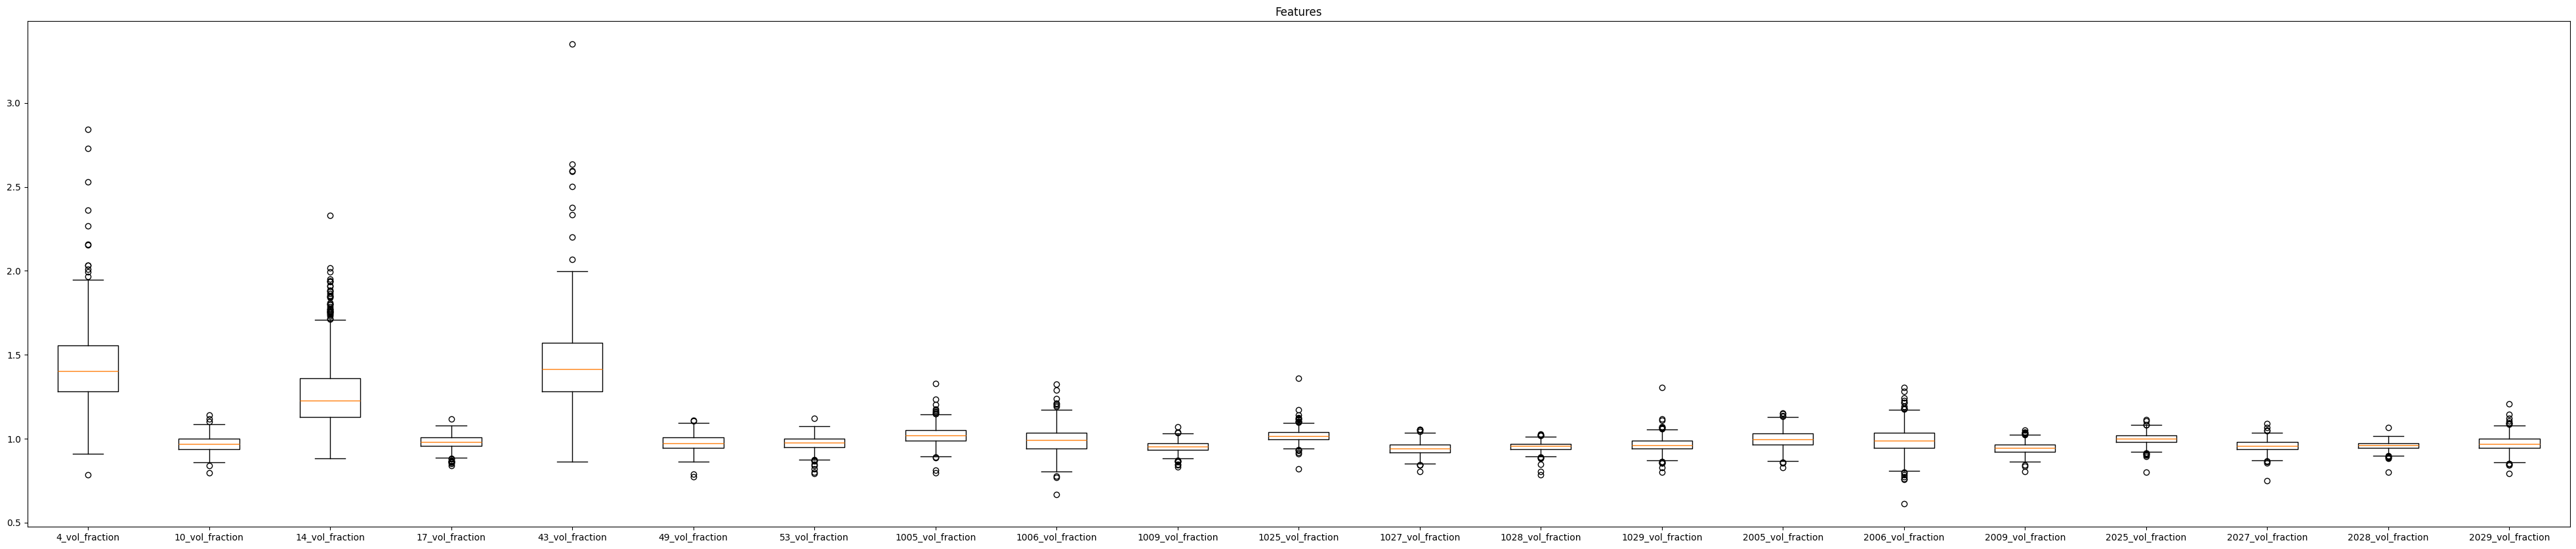

In [5]:
IMPORTANT_TISSUES = [43, 4, 53, 17, 49, 10, 42, 3, 2006, 1006, 2009, 1009, 2029, 1029, 2027, 1027, 2028, 1028, 2025, 1025, 2005, 1005, 14]
# IMPORTANT_TISSUES = None
loader_logitudinal_tb = features_loader_longitudinal_tissue_based.FeaturesLoader
nb_tissues = 96
metrics_name = ['vol_fraction']
matching_ids = pil.get_matching_ids()


reader_logitudinal_tb = loader_logitudinal_tb(nb_tissues, matching_ids)
data_logitudinal_tb = reader_logitudinal_tb.get_df(tissue_ids=IMPORTANT_TISSUES,
                                                   metrics_name=metrics_name,
                                                   remove_tissues=False,
                                                   remove_metrics=False,
                                                    return_patient_id=True, 
                                                    id_patients=data_ids_demographic,
                                                    remove_patients=False)

data_ids_logitudinal_tb = data_logitudinal_tb.pop('patient_id').astype(int).tolist()
data_columns_logitudinal_tb = data_logitudinal_tb.columns.tolist()

print(data_logitudinal_tb.shape)
display(data_logitudinal_tb.head())
vis.plot_data_voxplot(data_logitudinal_tb, data_columns_logitudinal_tb, figsize=(50,10))



## Cross-sectional features

### Tissue based

(685, 96)


,0_vol_hunt3,2_vol_hunt3,4_vol_hunt3,5_vol_hunt3,7_vol_hunt3,8_vol_hunt3,10_vol_hunt3,11_vol_hunt3,12_vol_hunt3,13_vol_hunt3,...,2024_vol_hunt3,2025_vol_hunt3,2026_vol_hunt3,2027_vol_hunt3,2028_vol_hunt3,2029_vol_hunt3,2030_vol_hunt3,2031_vol_hunt3,2034_vol_hunt3,2035_vol_hunt3
0,7362837.0,251849.0,9959.0,643.0,15711.0,52808.0,6804.0,3554.0,4048.0,1900.0,...,9908.0,8721.0,2624.0,10515.0,22293.0,8908.0,16239.0,7368.0,724.0,5918.0
1,7148477.0,295211.0,24309.0,639.0,16315.0,53240.0,6504.0,3628.0,4876.0,2059.0,...,10135.0,11417.0,2977.0,13956.0,27723.0,12581.0,16050.0,10963.0,654.0,6681.0
2,7203283.0,272962.0,31229.0,1493.0,15202.0,54816.0,6983.0,3781.0,5230.0,2100.0,...,10867.0,8666.0,2751.0,12687.0,27843.0,8852.0,17330.0,8428.0,1151.0,7282.0
3,7363532.0,254633.0,9134.0,358.0,14728.0,46183.0,6511.0,3435.0,4032.0,1871.0,...,10143.0,9341.0,2297.0,10405.0,22813.0,10346.0,15083.0,8177.0,709.0,5114.0
4,7312992.0,253837.0,16057.0,590.0,17214.0,54090.0,6181.0,3403.0,4154.0,1921.0,...,9903.0,8154.0,2585.0,10418.0,25569.0,9110.0,14004.0,8251.0,671.0,5273.0


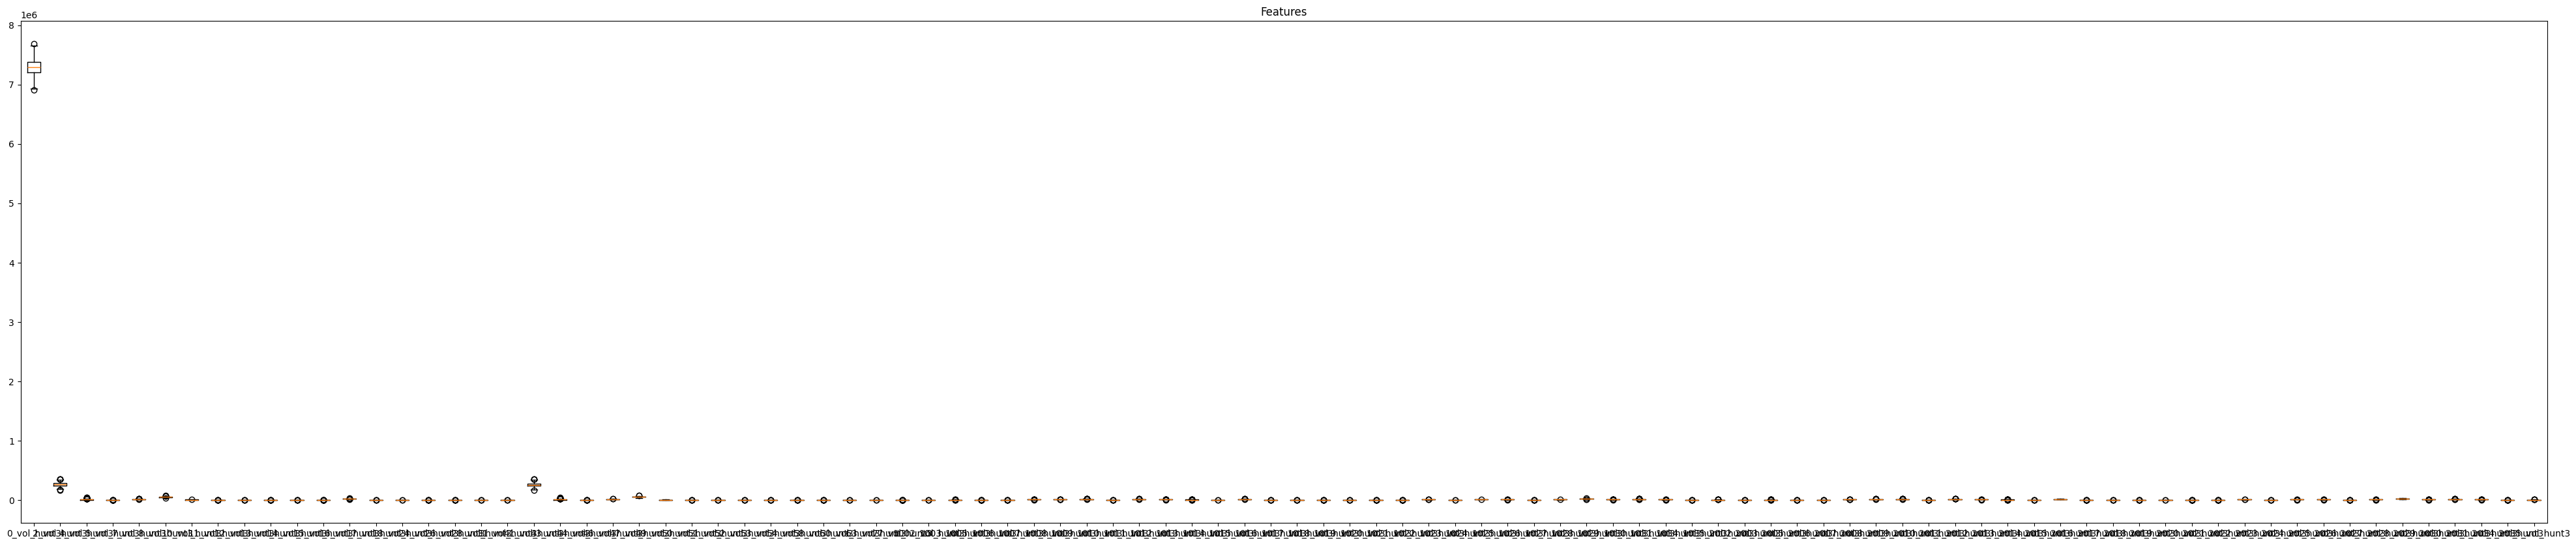

In [6]:
IMPORTANT_TISSUES = [43, 4, 53, 17, 49, 10, 42, 3, 2006, 1006, 2009, 1009, 2029, 1029, 2027, 1027, 2028, 1028, 2025, 1025, 2005, 1005, 14]
IMPORTANT_TISSUES = None
loader_cross_sectional_tb = features_loader_cross_sectional_tissue_based.FeaturesLoader
nb_tissues = 96
metrics_name = ['vol_hunt3']
matching_ids = pil.get_matching_ids()


reader_cross_sectional_tb = loader_cross_sectional_tb(nb_tissues, matching_ids)
data_cross_sectional_tb = reader_cross_sectional_tb.get_df(tissue_ids=IMPORTANT_TISSUES,
                                                   metrics_name=metrics_name,
                                                   remove_tissues=False,
                                                   remove_metrics=False,
                                                    return_patient_id=True, 
                                                    id_patients=data_ids_demographic,
                                                    remove_patients=False)

data_ids_cross_sectional_tb = data_cross_sectional_tb.pop('patient_id').astype(int).tolist()
data_columns_cross_sectional_tb = data_cross_sectional_tb.columns.tolist()

print(data_cross_sectional_tb.shape)
display(data_cross_sectional_tb.head())
vis.plot_data_voxplot(data_cross_sectional_tb, data_columns_cross_sectional_tb, figsize=(50,10))



# Correlation

In [8]:
# data_logitudinal_wbb["age_hunt3"] = data_demographic["age_hunt3"]
# data_logitudinal_wbb["age_hunt4"] = data_demographic["age_hunt4"]
# data = pd.concat([data_demographic, data_logitudinal_wbb], axis=1)

data = pd.concat([data_demographic, data_logitudinal_wbb, data_cross_sectional_tb], axis=1)
corr_df, to_drop = uml.correlation_df(data, corr_th=0.9)

print(f"High correlated: {to_drop}")
# vis.plot_data_precomputed_correlation_df(corr_df, figsize=(70, 60))
vis.plot_data_precomputed_correlation_df(corr_df, figsize=(150, 100))
# vis.plot_data_precomputed_correlation_df(corr_df, figsize=(20, 20))


High correlated: ['age_hunt3', 'bpf_hunt3', 'bpf_dif', '0_vol_hunt3', '2_vol_hunt3', '4_vol_hunt3', '7_vol_hunt3', '8_vol_hunt3', '10_vol_hunt3', '11_vol_hunt3', '12_vol_hunt3', '28_vol_hunt3', '1035_vol_hunt3']


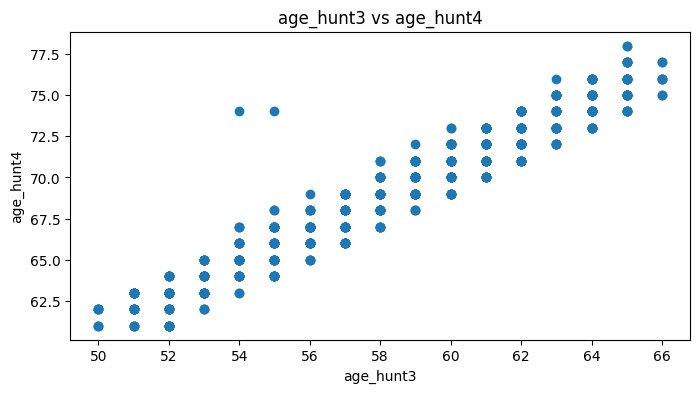

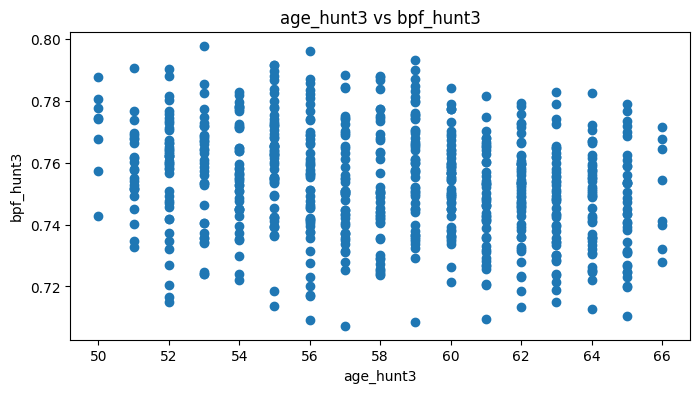

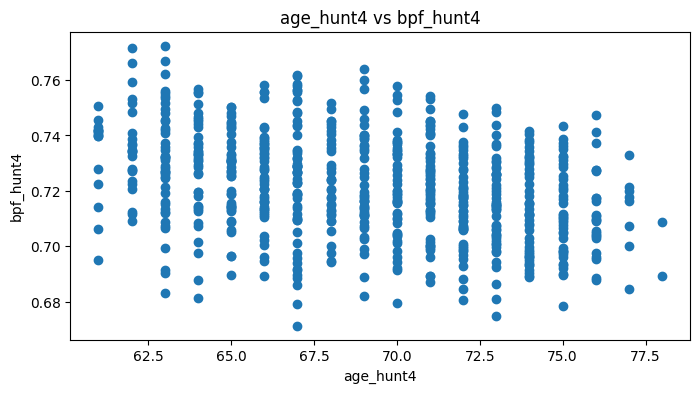

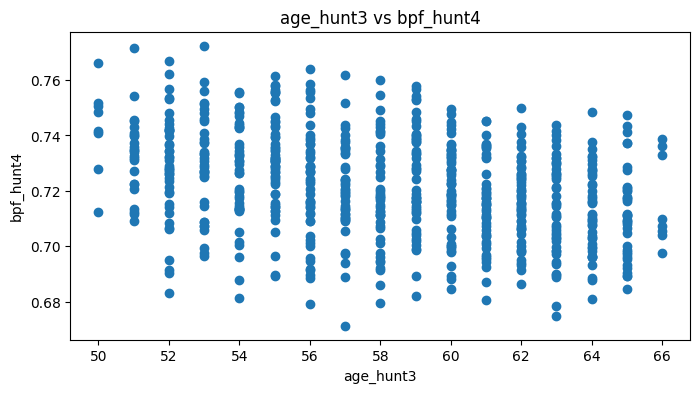

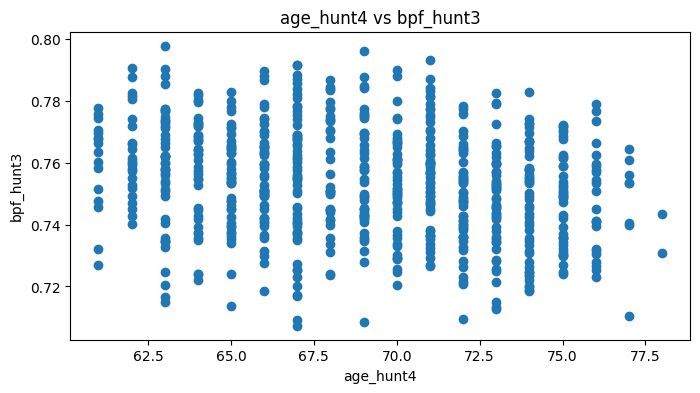

In [ ]:
vis.plot_2D_points(data_demographic["age_hunt3"], data_demographic["age_hunt4"], "age_hunt3", "age_hunt4", figsize=(8,4))

vis.plot_2D_points(data_demographic["age_hunt3"], data_logitudinal_wbb["bpf_hunt3"], "age_hunt3", "bpf_hunt3", figsize=(8,4))
vis.plot_2D_points(data_demographic["age_hunt4"], data_logitudinal_wbb["bpf_hunt4"], "age_hunt4", "bpf_hunt4", figsize=(8,4))

vis.plot_2D_points(data_demographic["age_hunt3"], data_logitudinal_wbb["bpf_hunt4"], "age_hunt3", "bpf_hunt4", figsize=(8,4))
vis.plot_2D_points(data_demographic["age_hunt4"], data_logitudinal_wbb["bpf_hunt3"], "age_hunt4", "bpf_hunt3", figsize=(8,4))


# Preprocessing

In [ ]:
# def remove_outliers_zscore(data, threshold=3):
#     z_scores = stats.zscore(data)
#     abs_z_scores = np.abs(z_scores)
#     filtered_data = data[(abs_z_scores < threshold).all(axis=1)]
#     return filtered_data

def remove_outliers_zscore(data, threshold=3):
    z_scores = stats.zscore(data)
    abs_z_scores = np.abs(z_scores)
    filtered_indices = np.where((abs_z_scores >= threshold).any(axis=1))[0]
    filtered_data = data[(abs_z_scores < threshold).all(axis=1)]
    removed_indices = np.delete(np.arange(len(data)), filtered_indices)
    return filtered_data, removed_indices

def standarize_and_normalize(data):
    scaler = StandardScaler()
    data_standardized = scaler.fit_transform(data)

    normalizer = MinMaxScaler()
    data_normalized = normalizer.fit_transform(data_standardized)
    return data_normalized

(668, 4)
(668,)


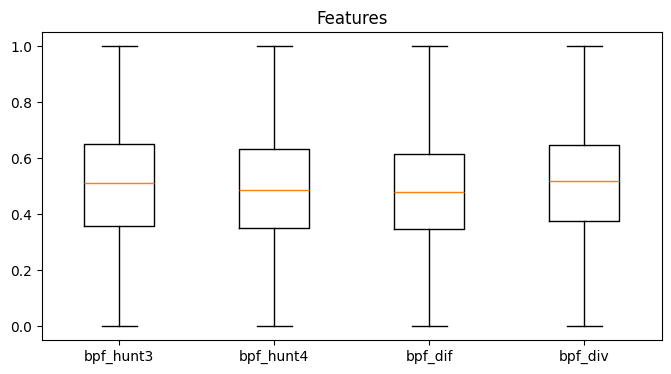

In [ ]:
data_logitudinal_wbb_prep, removed_indices = remove_outliers_zscore(data_logitudinal_wbb, 2.5)
data_logitudinal_wbb_prep = standarize_and_normalize(data_logitudinal_wbb_prep)
data_logitudinal_wbb_prep_df = pd.DataFrame(data_logitudinal_wbb_prep, columns=data_columns_logitudinal_wbb)


vis.plot_data_voxplot(data_logitudinal_wbb_prep, data_columns_logitudinal_wbb, figsize=(8,4))
print(data_logitudinal_wbb_prep_df.shape)
print(removed_indices.shape)